In [2]:
## If the dataset has been uploaded to Google Drive.
!pip install -U -q PyDrive
import os
from pydrive.auth import GoogleAuth
from pydrive.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials

# 1. Authenticate and create the PyDrive client.
auth.authenticate_user()
gauth = GoogleAuth()
gauth.credentials = GoogleCredentials.get_application_default()
drive = GoogleDrive(gauth)

# 2. Mount Drive
## Images as well as annotations are present 

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
!pip install pydub
!pip install noisereduce
!pip install soundfile
!apt install ffmpeg

Reading package lists... Done
Building dependency tree       
Reading state information... Done
ffmpeg is already the newest version (7:3.4.8-0ubuntu0.2).
0 upgraded, 0 newly installed, 0 to remove and 15 not upgraded.


In [7]:
path_in = 'drive/My Drive/Data_Hindi_English/4_Hindi/Male/5_four_hindi_male.wav'

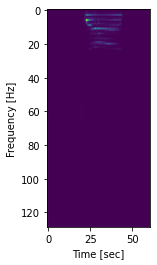

In [8]:
import numpy as np
from scipy import signal
from scipy.io import wavfile
import matplotlib.pyplot as plt

# Here, file_name is a '.wav' file.
## plots spectrogram of the audio
def getSpectrogram(path_to_file):
	sample_rate, samples = wavfile.read(path_to_file)
	frequencies, times, spectrogram = signal.spectrogram(samples, sample_rate)
	
	plt.pcolormesh(times, frequencies, spectrogram)
	plt.imshow(spectrogram)
	plt.ylabel('Frequency [Hz]')
	plt.xlabel('Time [sec]')
	plt.show()
 
getSpectrogram(path_in)

In [11]:
from pydub.silence import detect_nonsilent
from pydub import AudioSegment

## This function takes in path to file, returns a pydub.AudioSegment
def removeSilence(path_to_file, silence_threshold = -35.0, iter_size=10):
	
	audio = AudioSegment.from_file(path_to_file, format = "wav")
	iter_ind_front = 0
	while iter_ind_front<len(audio) and audio[iter_ind_front:iter_ind_front+iter_size].dBFS < silence_threshold:
		iter_ind_front+=iter_size
		
	audio_rev = audio.reverse()
	iter_ind_back = 0
	while iter_ind_back<len(audio_rev) and audio_rev[iter_ind_back:iter_ind_back+iter_size].dBFS < silence_threshold:
		iter_ind_back+=iter_size
	
	total_length = len(audio)
	cropped_audio = audio[iter_ind_front:total_length-iter_ind_back]
	return cropped_audio

removeSilence(path_in)

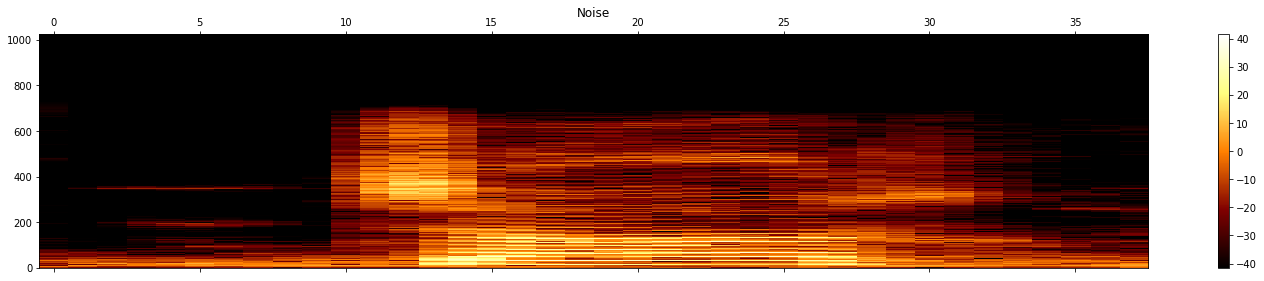

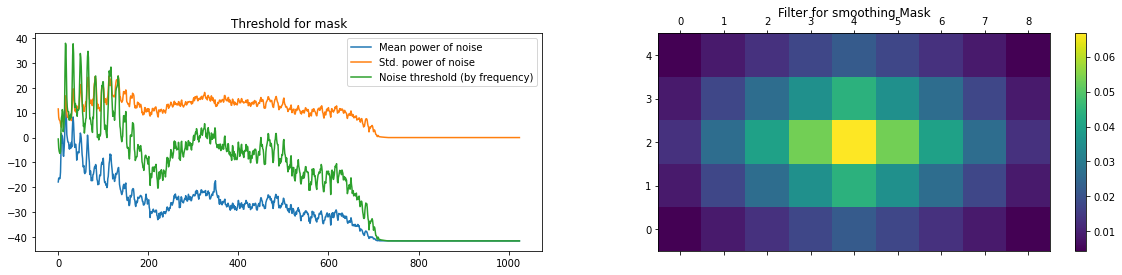

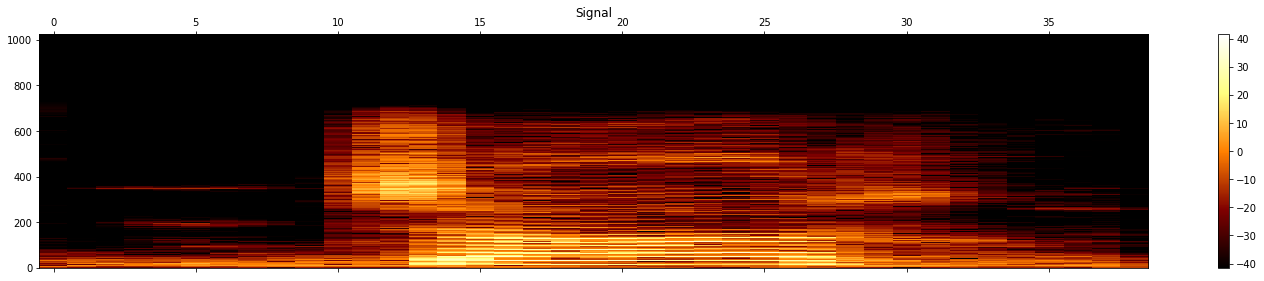

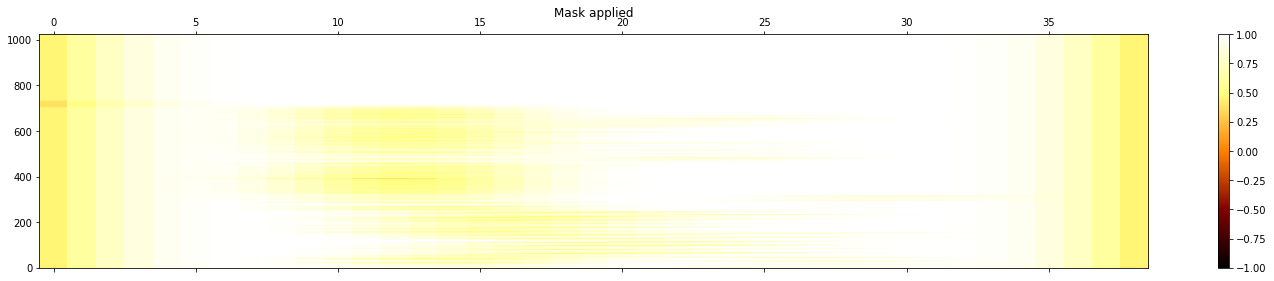

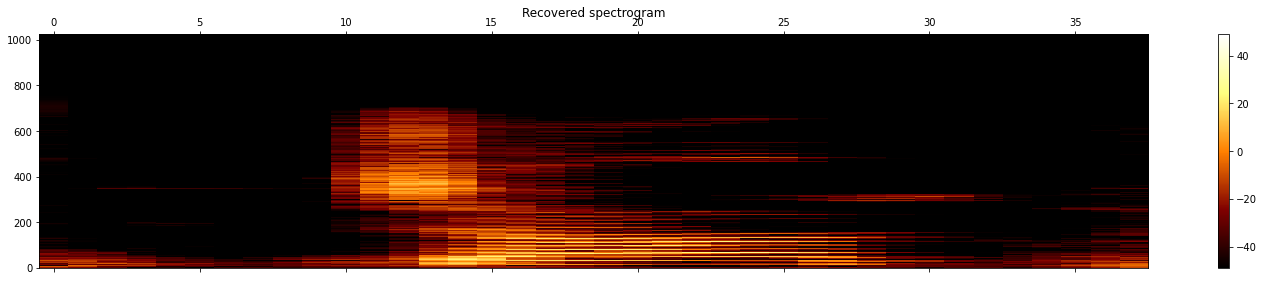

In [15]:
import noisereduce as nr
import librosa
import soundfile as sf

## This function takes in path to file, returns a pydub.AudioSegment
def removeNoise(path_to_file):
  
  data, sample_rate = librosa.load(path_to_file)
  reduced_noise = nr.reduce_noise(audio_clip=data, noise_clip = data[0:], verbose=True)
  sf.write(path_to_file,reduced_noise, 16000)
  reduced_noise = AudioSegment.from_file(path_to_file, format = "wav")
  return reduced_noise

removeNoise(path_in)

In [19]:
# Convert to proper wav file format
import librosa
import soundfile as sf

path_in = "drive/My Drive/Data_Hindi_English/9_Hindi/Female/19_nine_hindi_female.wav"
path_out = "drive/My Drive/Data_Hindi_English/9_Hindi/Female/19_nine_hindi_female_up.wav"

def fix_wave(path_in, path_out):

  x,_ = librosa.load(path_in, sr=16000)
  sf.write(path_out, x, 16000)
  audio = AudioSegment.from_file(path_out, format = "wav")
  return audio

fix_wave(path_in, path_out)